本notebook会估计带同期解释变量的 AR(1)。使用前面的 2012–2024 年训练窗口，纳入汇率变化率的 t−1 项、七个经济因子及政策事件 dummy进行回归。铁矿石使用 `iron_ore_exports_log_change_monthly.csv` 的有填充版本。2025 年以后的数据不参与拟合、选项设置或结果检验。

This notebook estimates an AR(1) with contemporaneous regressors. It uses the 2012–2024 training window from the earlier notebooks, the lagged exchange-rate change, all seven economic factors, and policy event indicators. Iron ore uses the filled `iron_ore_exports_log_change_monthly.csv` series. Observations from 2025 onward are excluded from estimation, specification choices, and diagnostics.

AR(1) 回归模型/AR(1) regression model:

$$
y_t=\alpha+\phi y_{t-1}+\sum_{j=1}^{7}\beta_j x_{j,t}
+\sum_{g=1}^{G}\gamma_g D_{g,t}+u_t.
$$

$$
y_t=100\left[\log E_t-\log E_{t-1}\right],
$$

In [ ]:
# import packages
from pathlib import Path
import platform
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import statsmodels
import statsmodels.api as sm
from IPython.display import display, Markdown
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.tsaplots import plot_acf


{'Python': '3.13.5', 'pandas': '3.0.6', 'numpy': '2.5.4', 'scipy': '1.18.1', 'statsmodels': '0.15.0'}


显著性水平设为 5%。主结果使用 OLS 系数及 Newey–West HAC 标准误，Bartlett 权重、12 个月带宽和有限样本缩放，采用渐近正态 z 检验。另展示 6、18 个月带宽及近似 t 参考分布，检查结论是否依赖这些选择。

The significance level is 5%. Main results use OLS coefficients and Newey–West HAC standard errors, with Bartlett weights, a 12-month bandwidth, a finite-sample scaling correction, and asymptotic normal z tests. Bandwidths of 6 and 18 months and an approximate t reference are also shown. 

In [ ]:
# set up paths and constants
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/final_monthly/USDSLE_monthly.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or notebook directory.")
DATA = ROOT / "data/final_monthly"
TRAIN_START, TRAIN_END = pd.Timestamp("2012-01-31"), pd.Timestamp("2024-12-31")
ALPHA, HAC_LAGS = 0.05, 12
BG_LAGS = (1, 6, 12)
calendar = pd.date_range(TRAIN_START, TRAIN_END, freq="ME", name="date")
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 45)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

FACTOR_FILES = {
    "base_money": "base_money_log_change_monthly.csv",
    "fx_reserves": "fx_reserves_log_change_monthly.csv",
    "fuel_imports": "fuel_imports_log_change_monthly.csv",
    "food_imports": "food_imports_log_change_monthly.csv",
    "iron_ore_exports": "iron_ore_exports_log_change_monthly.csv",
    "government_debt": "general_government_gross_debt_annual_change_pp_monthly.csv",
    "current_account": "current_account_balance_annual_change_pp_monthly.csv",
}
LABELS = {
    "fx_lag1": "汇率滞后一期 / FX change, lag 1",
    "base_money": "基础货币 / Base money",
    "fx_reserves": "外汇储备 / FX reserves",
    "fuel_imports": "燃料进口 / Fuel imports",
    "food_imports": "食品进口 / Food imports",
    "iron_ore_exports": "铁矿石出口 / Iron ore exports",
    "government_debt": "政府债务 / Government debt",
    "current_account": "经常账户 / Current account",
}
factors = list(FACTOR_FILES)
continuous = ["fx_lag1", *factors]
annual_factors = ["government_debt", "current_account"]
assert len(factors) == 7
assert not any("NO_FILL" in f for f in FACTOR_FILES.values())


先按完整月历对齐，再生成滞后项，最后删除模型所需变量缺失的行。这样不会把缺失月份两侧的数据误当作相邻月份。代码核查重复日期、月末日期、非有限值和 dummy 的 0/1 编码。只读取指定数值列，年度数据的文字分类列不进入模型。

Align observations to the complete monthly calendar, construct the lag, and then remove incomplete model rows. This prevents a missing month from creating a false one-month lag. Checks cover duplicate dates, month-end dates, nonfinite values, and binary policy indicators. Only the named numeric column is read; annual-data classification text is excluded.

2012 年 1 月没有样本内 t−1 值，因此回归从 2 月开始。文件首个汇率变化值为 0，其生成过程在本笔记本中无法核实。主模型保留提供的数据，后面另做删除 2012 年 2 月的边界敏感性检查，避免结论仅依赖这个初始滞后值。

January 2012 has no within-window lag, so estimation starts in February. The first supplied FX change is zero and its construction cannot be verified here. The main model preserves the supplied data. A later boundary sensitivity check omits February 2012 to assess dependence on this initial lag value.

In [ ]:
def read_training(filename, columns):
    frame = pd.read_csv(DATA / filename, usecols=["date", *columns])
    dates = pd.to_datetime(frame.pop("date"), format="%Y-%m-%d", errors="raise")
    inside = dates.between(TRAIN_START, TRAIN_END)
    frame = frame.loc[inside].copy()
    frame.index = pd.DatetimeIndex(dates.loc[inside], name="date")
    if frame.index.hasnans or frame.index.has_duplicates:
        raise ValueError(f"Invalid or duplicate training dates: {filename}")
    if not frame.index.is_month_end.all():
        raise ValueError(f"Expected month-end dates: {filename}")
    frame = frame.apply(pd.to_numeric, errors="raise").astype(float)
    if np.isinf(frame.to_numpy()).any():
        raise ValueError(f"Infinite observations: {filename}")
    return frame.sort_index().reindex(calendar)

# load data
raw_y = read_training("USDSLE_monthly.csv", ["USDSLE_monthly"]).iloc[:, 0].rename("fx_change")
factor_data = pd.DataFrame({
    name: read_training(file, [Path(file).stem]).iloc[:, 0]
    for name, file in FACTOR_FILES.items()
})
policy_file = "Sierra_Leone_Policy_Event_Dummies_monthly.csv"
policy_columns = [c for c in pd.read_csv(DATA / policy_file, nrows=0).columns if c != "date"]
policy_data = read_training(policy_file, policy_columns)
if not policy_data.stack().isin([0.0, 1.0]).all():
    raise ValueError("Policy indicators must be 0 or 1.")

# combine data and double-check for missing months
aligned = pd.concat([raw_y, raw_y.shift(1).rename("fx_lag1"), factor_data, policy_data], axis=1)
missing = aligned.isna().sum().rename("missing_months")
display(missing.loc[missing.gt(0)].to_frame())
excluded_dates = aligned.index[aligned.isna().any(axis=1)]
sample = aligned.dropna().copy()
expected = pd.date_range(sample.index.min(), sample.index.max(), freq="ME", name="date")
if not sample.index.equals(expected):
    raise ValueError("Internal missing months: serial diagnostics require a continuous sample.")
if len(sample) <= 60:
    raise ValueError("Insufficient observations for this specification.")
annual_counts = sample[annual_factors].groupby(sample.index.year).nunique()
if annual_counts.gt(1).any().any():
    raise ValueError("An annual factor varies within a calendar year.")
display(pd.DataFrame({
    "variable / 变量": [LABELS[c] for c in continuous],
    "n": sample[continuous].count().values,
    "mean": sample[continuous].mean().values,
    "sd": sample[continuous].std(ddof=1).values,
    "zero_months": sample[continuous].eq(0).sum().values,
}, index=continuous))
print(f"Sample: {sample.index.min():%Y-%m} to {sample.index.max():%Y-%m}; n={len(sample)}")
print("Excluded months:", [d.strftime("%Y-%m") for d in excluded_dates])
print(f"Annual periods: {len(annual_counts)}; source FX first value: {raw_y.iloc[0]:g}")

,missing_months
fx_lag1,1


,variable / 变量,n,mean,sd,zero_months
fx_lag1,"汇率滞后一期 / FX change, lag 1",155,1.07192,4.83353,18
base_money,基础货币 / Base money,155,1.6416,5.26106,1
fx_reserves,外汇储备 / FX reserves,155,-0.00764195,5.3293,0
fuel_imports,燃料进口 / Fuel imports,155,0.495827,81.6248,0
food_imports,食品进口 / Food imports,155,0.358198,71.5358,0
iron_ore_exports,铁矿石出口 / Iron ore exports,155,0.524283,57.3909,41
government_debt,政府债务 / Government debt,155,1.62903,4.06184,12
current_account,经常账户 / Current account,155,2.43355,6.85478,0


Sample: 2012-02 to 2024-12; n=155
Excluded months: ['2012-01']
Annual periods: 13; source FX first value: 0


**政策 dummy 的可识别性 / Identifying policy indicators**

所有政策列都进入核查。完全相同的列合并为一个事件月份项，并列出原始名称。这里的 dummy 使用提供文件中的单月脉冲编码。

All policy columns are audited. Identical columns are combined into one event-month regressor, with their original names retained. The supplied one-month pulse encoding is used. 

每个有效事件项仅覆盖一个月。包含该项后，该月杠杆值为 1，OLS 残差会被拟合为 0。单个政策系数缺少重复事件信息，常规稳健标准误可能严重低估不确定性。因此政策部分仅报告系数和覆盖月份，不报告单事件或整组政策的 HAC 显著性。

Each active event regressor covers one month. Its leverage is one and OLS forces that month's residual to zero. Individual policy effects lack repeated-event information, so conventional robust standard errors may severely understate uncertainty. Policy results therefore report coefficients and dates without individual or joint policy HAC significance tests.

In [ ]:
# Identify policy events and create dummy variables
policy_groups, policy_design, policy_audit_rows = {}, {}, []
patterns = {}
for name in policy_columns:
    values = sample[name]
    if values.nunique() == 1:
        policy_audit_rows.append({"original_dummy": name, "ones": int(values.sum()),
                                 "model_term": None, "status": "no within-sample variation"})
        continue
    if values.sum() != 1:
        raise ValueError("Review event inference: this notebook expects singleton pulse indicators.")
    pattern = tuple(values.to_numpy())
    event_date = values.index[values.eq(1)][0]
    if pattern not in patterns:
        term = f"P_{event_date:%Y_%m}"
        patterns[pattern] = term
        policy_design[term] = values
        policy_groups[term] = []
    term = patterns[pattern]
    policy_groups[term].append(name)
    policy_audit_rows.append({"original_dummy": name, "ones": int(values.sum()),
                             "model_term": term, "status": "included; shared term if same month"})

# create dataframes for policy terms
policy_X = pd.DataFrame(policy_design, index=sample.index)
policy_terms = list(policy_X)
policy_audit = pd.DataFrame(policy_audit_rows)
event_mapping = pd.DataFrame([
    {"model_term": term, "month": policy_X.index[policy_X[term].eq(1)][0].strftime("%Y-%m"),
     "original_dummies": " + ".join(names), "events_in_month": len(names)}
    for term, names in policy_groups.items()
]).set_index("model_term")
display(policy_audit)
display(event_mapping.loc[event_mapping.events_in_month.gt(1)])
print(f"Original columns={len(policy_columns)}; zero/constant={policy_audit.model_term.isna().sum()}; "
      f"active original columns={policy_audit.model_term.notna().sum()}; identified terms={len(policy_X.columns)}")

,original_dummy,ones,model_term,status
0,D_DIAMOND_SANCTIONS_2000,0,NaN,no within-sample variation
1,D_IMF_PRGF_2001,0,NaN,no within-sample variation
2,D_POSTWAR_START_2002,0,NaN,no within-sample variation
3,D_HIPC_DECISION_2002,0,NaN,no within-sample variation
4,D_IMF_PRGF_2006,0,NaN,no within-sample variation
5,D_HIPC_MDRI_2006,0,NaN,no within-sample variation
6,D_SDR_GENERAL_2009,0,NaN,no within-sample variation
7,D_SDR_SPECIAL_2009,0,NaN,no within-sample variation
8,D_GST_START_2010,0,NaN,no within-sample variation
9,D_IMF_ECF_2010,0,NaN,no within-sample variation


,month,original_dummies,events_in_month
model_term,,,
P_2020_04,2020-04,D_IMF_ECF_REVIEW_2020 + D_CCRT_FIRST_TRANCHE_2020,2
P_2021_08,2021-08,D_REDENOM_ANNOUNCE_2021 + D_SDR_ALLOCATION_2021,2
P_2023_11,2023-11,D_IMF_ECF_REVIEW_B_2023 + D_FX_FACILITY_DISCLOSE_2023,2
P_2024_11,2024-11,D_IMF_ECF_2024 + D_WAYS_MEANS_COMMITMENT_2024,2


Original columns=40; zero/constant=13; active original columns=27; identified terms=23


**拟合与完整设计矩阵检查 / Estimation and full design checks**

主模型包含截距、一个汇率滞后、七个因子及可识别的政策月份项。重新检查完整设计矩阵的秩及 VIF。比较表中的纯 AR(1)、AR(1)+因子和完整模型使用相同月份，R²、调整后 R² 和 RMSE 都是样本内指标。单月政策项可以提高样本内拟合度，比较表不构成预测能力或政策有效性的检验。

The full model includes an intercept, one FX lag, seven factors, and the identifiable policy-month terms. Matrix rank and VIF are checked again on this full design. The AR(1), AR(1)+factors, and full models use identical observations. R², adjusted R², and RMSE are in-sample measures. Singleton event terms can improve fit, so this comparison does not test forecasting ability or policy effectiveness.

,n,parameters,residual_df,R2,adjusted_R2,RMSE_in_sample
model,,,,,,
AR(1),155,2,153,0.018017,0.0115988,4.77406
AR(1) + 7 factors,155,9,146,0.100606,0.051324,4.56889
AR(1) + 7 factors + policy,155,32,123,0.229273,0.0350251,4.22947


Intercept / 截距: 1.191320


,VIF_full_design
fx_lag1,1.07544
base_money,1.78707
fx_reserves,2.92275
fuel_imports,1.30427
food_imports,1.16285
iron_ore_exports,1.17685
government_debt,1.18483
current_account,1.11786


Full design rank=32/32; maximum VIF including policies=2.923 (fx_reserves)
Event months fitted exactly: 23; other months: 132


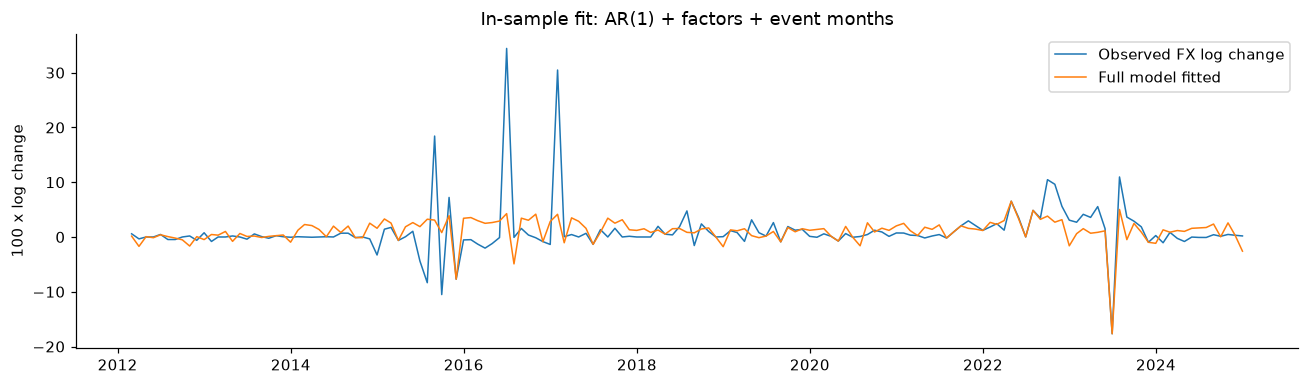

In [ ]:
# Fit full model and double-check rank and VIF

y = sample["fx_change"]
X = sm.add_constant(pd.concat([sample[continuous], policy_X], axis=1), has_constant="add")
rank = np.linalg.matrix_rank(X.to_numpy())
if rank != X.shape[1] or len(X) <= X.shape[1] + max(BG_LAGS):
    raise ValueError("Rank-deficient design or insufficient residual degrees of freedom.")
ols = sm.OLS(y, X, missing="raise").fit()


def hac_fit(design=X, target=y, lags=HAC_LAGS, use_t=False):
    return sm.OLS(target, design, missing="raise").fit(
        cov_type="HAC", cov_kwds={"maxlags": lags, "kernel": "bartlett", "use_correction": True},
        use_t=use_t,
    )


# check that HAC and OLS parameters are identical
hac = hac_fit()
assert np.allclose(hac.params, ols.params)
models = {
    "AR(1)": sm.OLS(y, X[["const", "fx_lag1"]]).fit(),
    "AR(1) + 7 factors": sm.OLS(y, X[["const", *continuous]]).fit(),
    "AR(1) + 7 factors + policy": ols,
}
fit_table = pd.DataFrame([
    {"model": name, "n": int(fit.nobs), "parameters": len(fit.params),
     "residual_df": int(fit.df_resid), "R2": fit.rsquared,
     "adjusted_R2": fit.rsquared_adj, "RMSE_in_sample": np.sqrt(np.mean(fit.resid**2))}
    for name, fit in models.items()
]).set_index("model")
display(fit_table)
print(f"Intercept / 截距: {ols.params['const']:.6f}")
vif = pd.Series({col: variance_inflation_factor(X.to_numpy(), i)
                 for i, col in enumerate(X.columns) if col != "const"}, name="VIF_full_design")
display(vif.loc[continuous].to_frame())
print(f"Full design rank={rank}/{X.shape[1]}; maximum VIF including policies={vif.max():.3f} ({vif.idxmax()})")

residuals = ols.resid.rename("residual")
leverage = pd.Series(ols.get_influence().hat_matrix_diag, index=X.index, name="leverage")
event_month = policy_X.sum(axis=1).gt(0)
assert np.allclose(leverage.loc[event_month], 1, atol=1e-10)
assert np.allclose(residuals.loc[event_month], 0, atol=1e-9)
print(f"Event months fitted exactly: {event_month.sum()}; other months: {(~event_month).sum()}")

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(y.index, y, label="Observed FX log change", linewidth=1)
ax.plot(y.index, ols.fittedvalues, label="Full model fitted", linewidth=1)
ax.set(ylabel="100 x log change", title="In-sample fit: AR(1) + factors + event months")
ax.legend()
fig.tight_layout()
plt.show()

对每个连续变量假设检验 $H_0:\beta_j=0$，AR 项检验 $H_0:\phi=0$。系数和 95% 置信区间采用 HAC(12)。系数的单位是：在其他变量固定时，解释变量增加一个单位对应的 $y_t$ 变化。月度因子的一个单位是 1 个 `100×对数变化` 单位；年度因子的一个单位是年度变化增加 1 个百分点。

Each continuous coefficient is tested against zero (hypothesis test); the AR hypothesis is $H_0:\phi=0$. Coefficients and 95% confidence intervals use HAC(12). A coefficient gives the change in $y_t$ per unit of its regressor, holding the others fixed. A monthly factor's unit is one unit of `100×log change`; an annual factor's unit is one percentage point of annual change.

七个经济因子属于同一个探索性检验组，使用 Holm 校正控制家族错误率。置信区间仍是逐项 95% 区间。另报告七因子整体和两项年度因子的稳健 Wald 检验，并在这两项组检验内进行 Holm 校正。AR 项是单独的预设检验。

The seven economic factors form one exploratory testing family, with Holm adjustment to control family-wise error. Confidence intervals remain individual 95% intervals. Robust Wald tests cover all seven factors and the two annual factors; these two group tests receive a separate Holm adjustment. The AR term is a separate prespecified test. 

In [5]:
ci = hac.conf_int(alpha=ALPHA)
coefficient_table = pd.DataFrame({
    "label": pd.Series(LABELS), "coefficient": hac.params.loc[continuous],
    "HAC12_SE": hac.bse.loc[continuous], "z": hac.tvalues.loc[continuous],
    "p_HAC12_z": hac.pvalues.loc[continuous],
    "CI95_low": ci.loc[continuous, 0], "CI95_high": ci.loc[continuous, 1],
}).reindex(continuous)
coefficient_table["p_Holm_7_factors"] = np.nan
coefficient_table.loc[factors, "p_Holm_7_factors"] = multipletests(
    coefficient_table.loc[factors, "p_HAC12_z"], alpha=ALPHA, method="holm"
)[1]
coefficient_table["reject_5pct"] = False
coefficient_table.loc[factors, "reject_5pct"] = coefficient_table.loc[factors, "p_Holm_7_factors"].lt(ALPHA)
coefficient_table.loc["fx_lag1", "reject_5pct"] = coefficient_table.loc["fx_lag1", "p_HAC12_z"] < ALPHA
display(coefficient_table)


def robust_joint_test(fit, terms):
    names = list(fit.params.index)
    R = np.zeros((len(terms), len(names)))
    for i, term in enumerate(terms):
        R[i, names.index(term)] = 1
    restriction_cov = R @ np.asarray(fit.cov_params()) @ R.T
    if np.linalg.matrix_rank(restriction_cov) != len(terms):
        raise ValueError(f"Singular covariance for joint test: {terms}")
    test = fit.wald_test(R, use_f=False, scalar=True)
    return float(test.statistic), float(test.pvalue)


joint_rows = []
for name, terms in {"All seven factors = 0": factors,
                    "Both annual factors = 0": annual_factors}.items():
    statistic, pvalue = robust_joint_test(hac, terms)
    joint_rows.append({"null": name, "chi2": statistic, "df": len(terms), "p_HAC12": pvalue})
joint_tests = pd.DataFrame(joint_rows).set_index("null")
joint_tests["p_Holm_2_groups"] = multipletests(joint_tests.p_HAC12, method="holm")[1]
display(joint_tests)

,label,coefficient,HAC12_SE,z,p_HAC12_z,CI95_low,CI95_high,p_Holm_7_factors,reject_5pct
fx_lag1,"汇率滞后一期 / FX change, lag 1",-0.144425,0.0894478,-1.61462,0.106392,-0.319739,0.0308898,NaN,False
base_money,基础货币 / Base money,0.058628,0.0820717,0.714351,0.47501,-0.10223,0.219486,1,False
fx_reserves,外汇储备 / FX reserves,-0.282021,0.143288,-1.96821,0.049044,-0.562861,-0.00118143,0.343308,False
fuel_imports,燃料进口 / Fuel imports,0.000337552,0.00310514,0.108708,0.913434,-0.00574841,0.00642351,1,False
food_imports,食品进口 / Food imports,0.00149488,0.00307167,0.486668,0.626493,-0.00452547,0.00751524,1,False
iron_ore_exports,铁矿石出口 / Iron ore exports,-0.00125023,0.00668649,-0.186979,0.851677,-0.0143555,0.011855,1,False
government_debt,政府债务 / Government debt,0.172812,0.103579,1.66841,0.0952336,-0.0301984,0.375823,0.571401,False
current_account,经常账户 / Current account,-0.0608126,0.0474645,-1.28122,0.200116,-0.153841,0.0322162,1,False


,chi2,df,p_HAC12,p_Holm_2_groups
null,,,,
All seven factors = 0,24.2658,7,0.00102301,0.00204603
Both annual factors = 0,5.98004,2,0.0502864,0.0502864


## 因子强弱 / Factor strength

不同单位下的原始系数不宜直接比较。这里同时报告：解释变量增加一个样本标准差对应的 $y_t$ 变化（$\hat\beta_j s_{x_j}$）；标准化系数（$\hat\beta_j s_{x_j}/s_y$）；删除该因子后的 partial R²（$(SSE_{reduced}-SSE_{full})/SSE_{reduced}$）。删除模型保留相同月份、AR 项、其余因子和政策项。图中的置信区间按相同标准差比例换算。

Raw coefficients in different units are not directly comparable. We report the response to a one-sample-SD increase ($\hat\beta_j s_{x_j}$), the standardized coefficient ($\hat\beta_j s_{x_j}/s_y$), and the partial R² from omitting one factor ($(SSE_{reduced}-SSE_{full})/SSE_{reduced}$). Reduced models keep the same observations, AR term, other factors, and policy terms. Plot intervals use the same SD scaling.

排序依据标准化系数绝对值。partial R² 描述额外样本内解释度，无法替代稳健显著性检验，也不代表因果贡献。政策系数单独展示，以避免把单次事件与连续变量的标准差效应混为一谈。

Ranking uses absolute standardized coefficients. Partial R² describes incremental in-sample fit; it does not replace robust inference or measure causal contribution. Policy coefficients are presented separately because a single event has a different interpretation from a continuous variable's SD effect.

,coefficient,p_HAC12_z,p_Holm_7_factors,effect_1SD_y_units,standardized_beta,std_CI95_low,std_CI95_high,partial_R2,delta_R2
fx_reserves,-0.282021,0.049044,0.343308,-1.50297,-0.310964,-0.620625,-0.00130267,0.0411599,0.0330848
government_debt,0.172812,0.0952336,0.571401,0.701936,0.14523,-0.0253785,0.315839,0.0225756,0.0178015
current_account,-0.0608126,0.200116,1,-0.416857,-0.0862472,-0.218185,0.0456905,0.00855992,0.00665432
base_money,0.058628,0.47501,1,0.308446,0.0638171,-0.111278,0.238912,0.00294815,0.00227894
food_imports,0.00149488,0.626493,1,0.106938,0.0221253,-0.0669801,0.111231,0.000545907,0.000420975
iron_ore_exports,-0.00125023,0.851677,1,-0.0717519,-0.0148454,-0.170459,0.140768,0.000242917,0.000187268
fuel_imports,0.000337552,0.913434,1,0.0275527,0.00570062,-0.0970797,0.108481,3.23267e-05,2.49159e-05


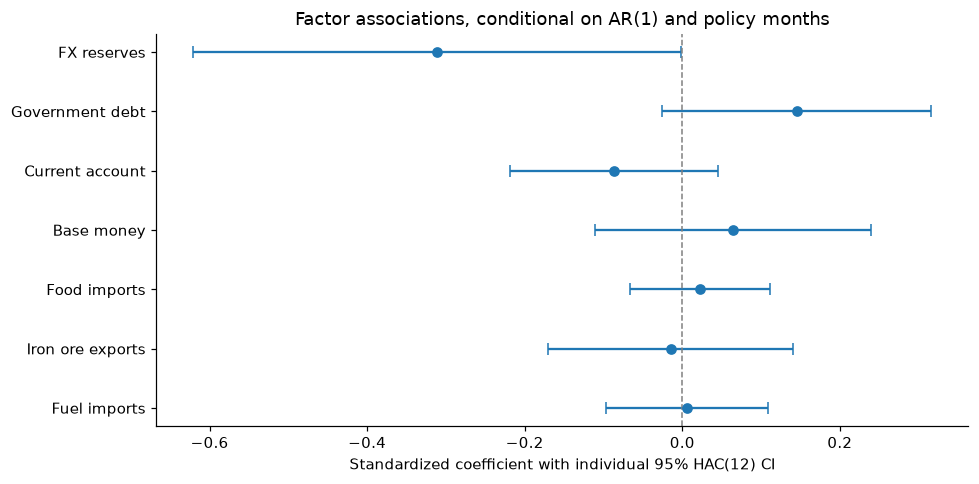

,month,original_dummies,events_in_month,coefficient_y_units,inference
model_term,,,,,
P_2013_10,2013-10,D_IMF_ECF_2013,1,0.683216,descriptive only: one observed event month
P_2014_05,2014-05,D_EBOLA_ONSET_2014,1,-1.0855,descriptive only: one observed event month
P_2014_09,2014-09,D_IMF_EBOLA_2014,1,-2.56593,descriptive only: one observed event month
P_2015_03,2015-03,D_IMF_EBOLA_2015,1,0.60405,descriptive only: one observed event month
P_2015_11,2015-11,D_IMF_ECF_REVIEW_2015,1,-7.83525,descriptive only: one observed event month
P_2016_11,2016-11,D_FUEL_SUBSIDY_2016,1,-3.51015,descriptive only: one observed event month
P_2017_06,2017-06,D_IMF_ECF_2017,1,-1.16759,descriptive only: one observed event month
P_2018_04,2018-04,D_TSA_ORDER_2018,1,-0.484109,descriptive only: one observed event month
P_2018_11,2018-11,D_IMF_ECF_2018,1,-3.32208,descriptive only: one observed event month


In [6]:
strength = coefficient_table.loc[factors, ["coefficient", "p_HAC12_z", "p_Holm_7_factors"]].copy()
sx, sy = sample[factors].std(ddof=1), y.std(ddof=1)
strength["effect_1SD_y_units"] = hac.params.loc[factors] * sx
strength["standardized_beta"] = strength.effect_1SD_y_units / sy
strength["std_CI95_low"] = ci.loc[factors, 0] * sx / sy
strength["std_CI95_high"] = ci.loc[factors, 1] * sx / sy
for term in factors:
    reduced = sm.OLS(y, X.drop(columns=term)).fit()
    strength.loc[term, "partial_R2"] = (reduced.ssr - ols.ssr) / reduced.ssr
    strength.loc[term, "delta_R2"] = ols.rsquared - reduced.rsquared
strength = strength.loc[strength.standardized_beta.abs().sort_values(ascending=False).index]
display(strength)

plot_data = strength.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(plot_data.standardized_beta, np.arange(len(plot_data)),
            xerr=np.vstack([plot_data.standardized_beta - plot_data.std_CI95_low,
                            plot_data.std_CI95_high - plot_data.standardized_beta]),
            fmt="o", capsize=4, color="tab:blue")
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_yticks(np.arange(len(plot_data)), [LABELS[x].split(" / ")[1] for x in plot_data.index])
ax.set(xlabel="Standardized coefficient with individual 95% HAC(12) CI",
       title="Factor associations, conditional on AR(1) and policy months")
fig.tight_layout()
plt.show()

policy_results = event_mapping.copy()
policy_results["coefficient_y_units"] = ols.params.loc[policy_results.index]
policy_results["inference"] = "descriptive only: one observed event month"
display(policy_results)

**边界敏感性 / Boundary sensitivity**

比较 HAC 带宽、z/t 参考分布，以及删除初始滞后值后的估计。t 参考使用残差自由度。每一列 p 值都在七因子组内单独进行 Holm 校正。

Compare HAC bandwidths, z/t references, and estimation after omitting the initial lag observation. Each p-value column receives its own seven-factor Holm adjustment.

In [7]:
sensitivity_fits = {
    "HAC6_z": hac_fit(lags=6), "HAC12_z": hac,
    "HAC18_z": hac_fit(lags=18), "HAC12_t": hac_fit(use_t=True),
    "omit_first_lag_HAC12_z": hac_fit(X.iloc[1:], y.iloc[1:]),
}
sensitivity_p = pd.DataFrame({name: fit.pvalues.loc[continuous]
                              for name, fit in sensitivity_fits.items()})
sensitivity_holm = pd.DataFrame({
    name: multipletests(fit.pvalues.loc[factors], method="holm")[1]
    for name, fit in sensitivity_fits.items()
}, index=factors)
display(sensitivity_p.rename_axis("raw_p_values"))
display(sensitivity_holm.rename_axis("Holm_p_values_7_factors"))
display(pd.DataFrame({"baseline_coefficient": hac.params.loc[continuous],
                      "omit_first_lag_coefficient": sensitivity_fits["omit_first_lag_HAC12_z"].params.loc[continuous]}))

,HAC6_z,HAC12_z,HAC18_z,HAC12_t,omit_first_lag_HAC12_z
raw_p_values,,,,,
fx_lag1,0.168896,0.106392,0.0579409,0.108954,0.107309
base_money,0.483185,0.47501,0.487826,0.476364,0.482776
fx_reserves,0.0505164,0.049044,0.0398315,0.0512935,0.0509643
fuel_imports,0.916596,0.913434,0.907071,0.913611,0.911492
food_imports,0.614615,0.626493,0.626241,0.62736,0.624174
iron_ore_exports,0.839472,0.851677,0.847803,0.851985,0.872298
government_debt,0.151531,0.0952336,0.0479642,0.0977773,0.0935483
current_account,0.359146,0.200116,0.196171,0.202526,0.20823


,HAC6_z,HAC12_z,HAC18_z,HAC12_t,omit_first_lag_HAC12_z
Holm_p_values_7_factors,,,,,
base_money,1,1,1,1,1
fx_reserves,0.353614,0.343308,0.278821,0.359055,0.35675
fuel_imports,1,1,1,1,1
food_imports,1,1,1,1,1
iron_ore_exports,1,1,1,1,1
government_debt,0.909188,0.571401,0.287785,0.586664,0.56129
current_account,1,1,0.980857,1,1


,baseline_coefficient,omit_first_lag_coefficient
fx_lag1,-0.144425,-0.144226
base_money,0.058628,0.057825
fx_reserves,-0.282021,-0.281158
fuel_imports,0.000337552,0.000345287
food_imports,0.00149488,0.00150717
iron_ore_exports,-0.00125023,-0.00111702
government_debt,0.172812,0.173341
current_account,-0.0608126,-0.0619822


下面将进行残差自相关的检验，使用 Breusch–Godfrey检验 1、6、12 阶残差自相关，原假设是对应阶数以内的残差相关系数全为 0。模型包含滞后因变量，因此不使用普通 Durbin–Watson 临界值判断。报告经典 BG 的 LM、F 形式及 p 值，三个 LM 检验进行 Holm 校正。

The following will be the test for residual autocorrelation. Breusch–Godfrey tests assess residual serial correlation through lags 1, 6, and 12. The null sets all residual-lag coefficients through that order to zero. Ordinary Durbin–Watson critical values are not used with a lagged dependent variable. Classical LM and F forms are shown, with Holm adjustment over the three LM tests.

为检查经典检验对异方差的敏感性，另在“残差对原解释变量及滞后残差”的辅助回归中，对残差滞后项做 HC1 稳健 Wald 检验。先在完整月历上生成残差滞后，再统一去掉前 12 个月，三个稳健检验使用相同辅助样本，并单独作 Holm 校正。

As a heteroskedasticity sensitivity check, auxiliary regressions explain residuals using the original regressors and lagged residuals, with HC1 robust Wald tests on the residual-lag block. Lags are constructed on the full calendar before removing the first 12 months. The three robust tests share this auxiliary sample and receive their own Holm adjustment. Policy months remain in the time sequence; deleting them would join nonadjacent months. 

In [8]:
bg_options = {"result_object": False} if "result_object" in inspect.signature(acorr_breusch_godfrey).parameters else {}
serial_rows = []
lagged_residuals = pd.DataFrame({f"resid_lag{k}": residuals.shift(k)
                               for k in range(1, max(BG_LAGS) + 1)})
aux_index = lagged_residuals.dropna().index
for order in BG_LAGS:
    lm, lm_p, fstat, f_p = acorr_breusch_godfrey(ols, nlags=order, **bg_options)
    lag_terms = [f"resid_lag{k}" for k in range(1, order + 1)]
    aux_X = pd.concat([X.loc[aux_index], lagged_residuals.loc[aux_index, lag_terms]], axis=1)
    # A pulse outside the trimmed sample has become an all-zero column.
    aux_X = aux_X.loc[:, (aux_X.ne(0).any(axis=0))]
    if np.linalg.matrix_rank(aux_X) != aux_X.shape[1]:
        raise ValueError("Auxiliary autocorrelation design is rank deficient.")
    aux = sm.OLS(residuals.loc[aux_index], aux_X).fit(cov_type="HC1", use_t=False)
    robust_stat, robust_p = robust_joint_test(aux, lag_terms)
    serial_rows.append({"lags": order, "BG_LM": lm, "BG_LM_p": lm_p,
                       "BG_F": fstat, "BG_F_p": f_p, "aux_n": len(aux_index),
                       "HC1_Wald_chi2": robust_stat, "HC1_Wald_p": robust_p})
serial_tests = pd.DataFrame(serial_rows).set_index("lags")
serial_tests["BG_LM_p_Holm3"] = multipletests(serial_tests.BG_LM_p, method="holm")[1]
serial_tests["HC1_p_Holm3"] = multipletests(serial_tests.HC1_Wald_p, method="holm")[1]
display(serial_tests)

,BG_LM,BG_LM_p,BG_F,BG_F_p,aux_n,HC1_Wald_chi2,HC1_Wald_p,BG_LM_p_Holm3,HC1_p_Holm3
lags,,,,,,,,,
1,0.190525,0.66248,0.150146,0.699071,143,0.0671552,0.795525,1,1
6,2.23674,0.896689,0.285517,0.942817,143,2.43715,0.875435,1,1
12,40.1922,6.68133e-05,3.23826,0.000510106,143,7.71866,0.806711,0.00020044,1


## 异方差与正态性 / Heteroskedasticity and normality

使用 Koenker 版本的 Breusch–Pagan（BP）检验，原假设为条件方差不随列出的连续解释变量变化；辅助变量为截距及八个连续项。主诊断使用非事件月份的残差，避免事件项强制为 0 的残差制造方差差异。全样本结果作为对照。该检查仅覆盖这种方差关系，不能据此排除所有异方差或波动聚集。完整 White 展开会加入大量平方及交互项，在本样本和大量脉冲项下不合适。见 [BP 文档](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_breuschpagan.html)。

The Koenker version of Breusch–Pagan tests whether conditional variance is unrelated to the listed continuous regressors, using an intercept and the eight continuous terms. The primary screen uses non-event residuals to avoid variance differences created by forced-zero event residuals. Full-sample results provide a comparison. This tests a particular variance relationship and cannot exclude all heteroskedasticity or volatility clustering. A full White expansion would add many squares and interactions in a sample already containing numerous pulses.

Jarque–Bera（JB）检验残差偏度与峰度是否符合正态分布，并配合 Q–Q 图。OLS 点估计本身不要求误差正态；厚尾会影响小样本推断和异常值敏感性。BP/JB 的参考分布依赖误差假设，若存在时间依赖，其 p 值只能作探索性诊断。这里不再加 ARCH-LM，以免在单月事件精确拟合、极端残差和自相关结论不稳的情况下叠加更多检验。见 [JB 文档](https://www.statsmodels.org/stable/generated/statsmodels.stats.stattools.jarque_bera.html)。

Jarque–Bera tests whether residual skewness and kurtosis match normality, supplemented by a Q–Q plot. OLS point estimation does not itself require normal errors; heavy tails affect small-sample inference and outlier sensitivity. BP/JB reference distributions rely on error assumptions and become exploratory under temporal dependence. ARCH-LM is omitted here because exact event fits, extreme residuals, and uncertain serial-correlation evidence already limit additional volatility tests.

,n,BP_LM,BP_LM_p,BP_F_p,JB,JB_p,skewness,kurtosis
sample,,,,,,,,
Non-event months (primary),132,12.1466,0.14478,0.144254,2780.15,0,3.66193,24.2566
All months (comparison),155,10.9407,0.20508,0.207182,4600.75,0,3.96816,28.4831


A displayed JB p=0 is numerical underflow; it is not a mathematically zero probability.


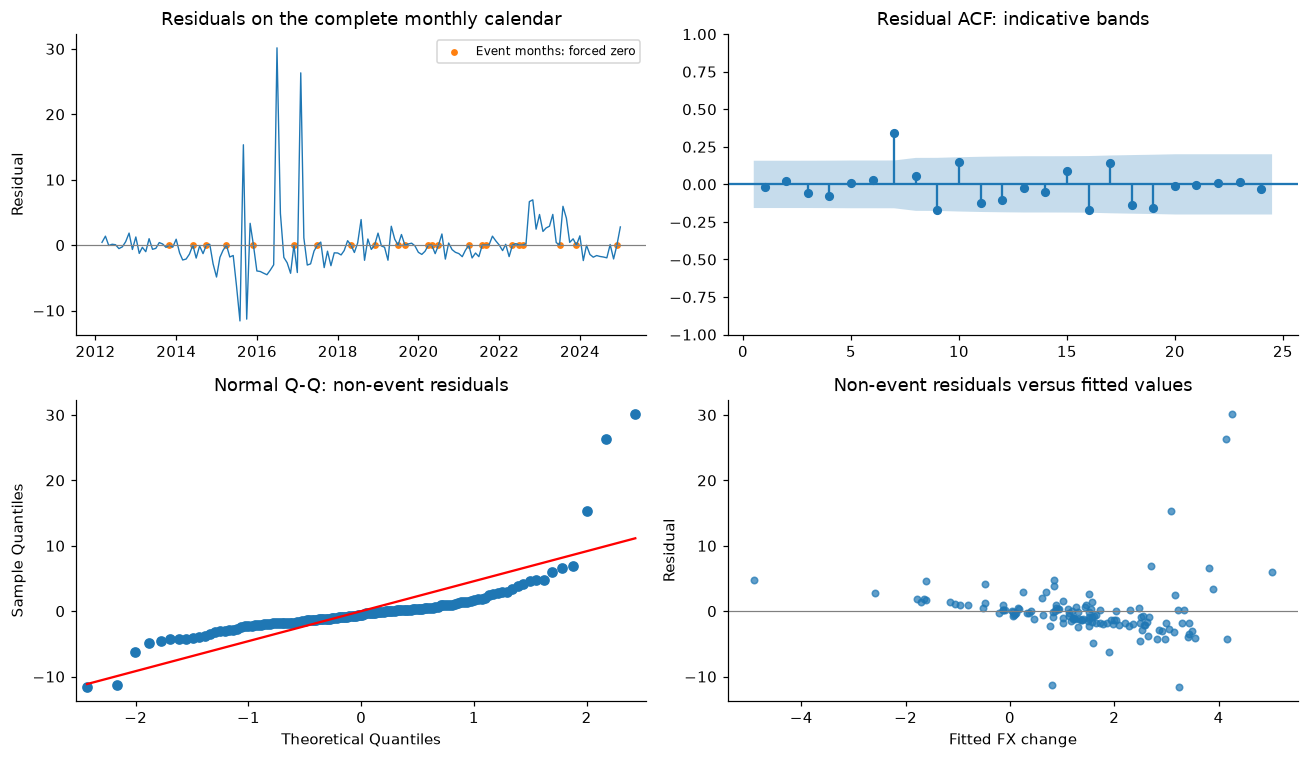

,observed_y,fitted_y,residual,leverage,share_of_full_SSE
date,,,,,
2016-06-30,34.4294,4.26285,30.1666,0.0827658,0.328208
2017-01-31,30.4871,4.14623,26.3409,0.0390945,0.25024
2015-08-31,18.428,3.08263,15.3454,0.0626739,0.0849284
2015-07-31,-8.34757,3.24526,-11.5928,0.0464489,0.0484702
2015-09-30,-10.5143,0.80513,-11.3194,0.123583,0.0462111
2022-10-31,9.62529,2.7037,6.92159,0.127073,0.0172786


In [9]:
distribution_rows = []
variance_X = X[["const", *continuous]]
for name, mask in {"Non-event months (primary)": ~event_month,
                   "All months (comparison)": pd.Series(True, index=X.index)}.items():
    e = residuals.loc[mask]
    bp_lm, bp_p, bp_f, bp_f_p = het_breuschpagan(e, variance_X.loc[mask], robust=True)
    jb_stat, jb_p, skewness, kurtosis = jarque_bera(e)
    distribution_rows.append({"sample": name, "n": len(e), "BP_LM": bp_lm,
                              "BP_LM_p": bp_p, "BP_F_p": bp_f_p,
                              "JB": jb_stat, "JB_p": jb_p,
                              "skewness": skewness, "kurtosis": kurtosis})
distribution_tests = pd.DataFrame(distribution_rows).set_index("sample")
display(distribution_tests)
print("A displayed JB p=0 is numerical underflow; it is not a mathematically zero probability.")

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(residuals.index, residuals, linewidth=0.9)
axes[0, 0].scatter(residuals.index[event_month], residuals.loc[event_month],
                   s=12, color="tab:orange", label="Event months: forced zero")
axes[0, 0].axhline(0, color="grey", linewidth=0.8)
axes[0, 0].set(title="Residuals on the complete monthly calendar", ylabel="Residual")
axes[0, 0].legend(fontsize=8)
plot_acf(residuals, lags=24, zero=False, ax=axes[0, 1], alpha=ALPHA)
axes[0, 1].set_title("Residual ACF: indicative bands")
sm.qqplot(residuals.loc[~event_month], line="s", ax=axes[1, 0])
axes[1, 0].set_title("Normal Q-Q: non-event residuals")
axes[1, 1].scatter(ols.fittedvalues.loc[~event_month], residuals.loc[~event_month], s=18, alpha=0.7)
axes[1, 1].axhline(0, color="grey", linewidth=0.8)
axes[1, 1].set(title="Non-event residuals versus fitted values", xlabel="Fitted FX change", ylabel="Residual")
fig.tight_layout()
plt.show()

# Inspect extreme observations without automatically removing or winsorizing them.
residual_review = pd.DataFrame({"observed_y": y, "fitted_y": ols.fittedvalues,
                                "residual": residuals, "leverage": leverage}).loc[~event_month]
residual_review["share_of_full_SSE"] = residual_review.residual.pow(2) / ols.ssr
residual_review = residual_review.loc[residual_review.residual.abs().sort_values(ascending=False).index]
display(residual_review.head(6))

## 残差与汇率的关系 / Residuals and the exchange rate

残差与当期 $y_t$ 的相关性不能用来检验模型是否合格。含截距 OLS 满足 $y_t=\hat y_t+\hat u_t$，残差与拟合值正交，因此 $\mathrm{corr}(\hat u,y)=\sqrt{1-R^2}$。残差与已纳入模型的 $y_{t-1}$ 的样本相关性也会按构造接近 0。下面验证这两项代数关系，不计算误导性的 Pearson p 值。

Residual correlation with current $y_t$ is not a model-adequacy test. OLS with an intercept gives $y_t=\hat y_t+\hat u_t$ and orthogonality between residuals and fitted values, implying $\mathrm{corr}(\hat u,y)=\sqrt{1-R^2}$. Sample correlation with the included $y_{t-1}$ is also approximately zero by construction. The table verifies these identities without misleading Pearson p-values.

本次因变量是汇率变化率。对未进入回归的汇率价格水平直接做残差相关显著性检验，会混入价格趋势和时间依赖，因此不作该检验。模型诊断依据前面的残差时序、BG/稳健辅助检验、方差筛查和 Q–Q 图。

The dependent variable is an exchange-rate change. A direct significance test against the exchange-rate price level would mix price trends and temporal dependence, so it is omitted. Model assessment instead uses the residual time plot, BG/robust auxiliary tests, variance screening, and Q–Q plot.

In [10]:
correlation_audit = pd.DataFrame({
    "correlation": [residuals.corr(y), residuals.corr(sample.fx_lag1), residuals.corr(ols.fittedvalues)],
    "OLS_identity": [np.sqrt(1 - ols.rsquared), 0.0, 0.0],
    "interpretation": ["mechanical relation with current dependent variable",
                       "orthogonality to an included regressor", "orthogonality to fitted values"],
}, index=["residual vs current FX change", "residual vs lagged FX change", "residual vs fitted change"])
display(correlation_audit)
assert np.allclose(correlation_audit.correlation, correlation_audit.OLS_identity, atol=1e-10)

,correlation,OLS_identity,interpretation
residual vs current FX change,0.87791,0.87791,mechanical relation with current dependent variable
residual vs lagged FX change,-5.12919e-16,0,orthogonality to an included regressor
residual vs fitted change,1.24275e-15,0,orthogonality to fitted values


## 结果解释 / Results interpretation

下面的文字由当前运行的结果生成，避免修改数据后仍保留旧数值。判断以主模型、七因子 Holm 校正，以及经典和稳健残差检验的共同证据为依据。

The following interpretation is generated from this execution so that reported values update with the results. It uses the main model, seven-factor Holm adjustment, and evidence from both classical and robust residual tests.

In [ ]:


def fmt_p(value):
    return "< 1e-300" if value == 0 else f"{value:.4g}"


top = strength.index[0]
significant = coefficient_table.loc[factors].index[coefficient_table.loc[factors, "reject_5pct"]].tolist()
sig_zh = "、".join(LABELS[t].split(" / ")[0] for t in significant) if significant else "无"
sig_en = ", ".join(LABELS[t].split(" / ")[1] for t in significant) if significant else "none"
primary = distribution_tests.loc["Non-event months (primary)"]
classic_reject = serial_tests.BG_LM_p_Holm3.lt(ALPHA).any()
robust_reject = serial_tests.HC1_p_Holm3.lt(ALPHA).any()
if classic_reject and not robust_reject:
    serial_zh = "经典 BG 与 HC1 稳健辅助检验结论不一致。自相关信号对推断方法敏感，不能确认残差已独立，也不能仅凭经典检验断定 AR(1) 必然不足。"
    serial_en = "Classical BG and the HC1 auxiliary tests disagree. Serial-correlation evidence is sensitive to the inference method. Residual independence is unconfirmed, while the classical test alone does not establish that AR(1) is inadequate."
elif classic_reject or robust_reject:
    serial_zh = "至少一组经校正的检验提示残差时间依赖，应检查动态设定。"
    serial_en = "At least one adjusted test family indicates temporal dependence; the dynamic specification needs review."
else:
    serial_zh = "这些检验未发现足够的时间依赖证据，但有限样本下的不拒绝无法证明残差独立。"
    serial_en = "These tests find insufficient evidence of temporal dependence; non-rejection in a finite sample does not establish independence."
bp_zh = "未拒绝所检验的同方差原假设" if primary.BP_LM_p >= ALPHA else "拒绝所检验的同方差原假设"
bp_en = "does not reject the tested homoskedasticity null" if primary.BP_LM_p >= ALPHA else "rejects the tested homoskedasticity null"
jb_zh = "拒绝正态性" if primary.JB_p < ALPHA else "未拒绝正态性"
jb_en = "rejects normality" if primary.JB_p < ALPHA else "does not reject normality"
top_two_share = residual_review.head(2).share_of_full_SSE.sum()
extreme_dates = ", ".join(residual_review.head(2).index.strftime("%Y-%m"))
reserve = coefficient_table.loc["fx_reserves"]
ar_zh = "当前证据不足以支持显著的一阶持续性。" if hac.pvalues['fx_lag1'] >= ALPHA else "当前设定下的一阶滞后系数达到 5% 显著性门槛。"
ar_en = "Current evidence does not support a statistically significant lag-1 effect." if hac.pvalues['fx_lag1'] >= ALPHA else "The lag-1 coefficient meets the 5% significance threshold in this specification."
joint_holm_p = joint_tests.loc['All seven factors = 0', 'p_Holm_2_groups']
joint_zh = "七因子联合零假设在组检验校正后仍被拒绝。这支持因子组合具有条件关联，单项检验尚无法稳定定位其中某个因子；两类检验针对不同假设。" if joint_holm_p < ALPHA else "七因子联合零假设在组检验校正后未被拒绝。"
joint_en = "The joint seven-factor null is rejected after the group-test adjustment. This supports a conditional association for the factor block, while individual tests do not reliably identify a particular factor. The tests address different hypotheses." if joint_holm_p < ALPHA else "The joint seven-factor null is not rejected after the group-test adjustment."
display(Markdown(f"""
### 样本和拟合 / Sample and fit

完整模型使用 {len(y)} 个月、{len(ols.params)} 个参数，剩余自由度为 {int(ols.df_resid)}。R²={ols.rsquared:.3f}，调整后 R²={ols.rsquared_adj:.3f}，样本内 RMSE={np.sqrt(np.mean(residuals**2)):.3f}。{event_month.sum()} 个事件月份被单月 dummy 精确拟合，整体样本内解释力仍有限。年度因子的识别只来自 {len(annual_counts)} 个年度的变化。

The full model uses {len(y)} months and {len(ols.params)} parameters, leaving {int(ols.df_resid)} residual degrees of freedom. R²={ols.rsquared:.3f}, adjusted R²={ols.rsquared_adj:.3f}, and in-sample RMSE={np.sqrt(np.mean(residuals**2)):.3f}. The {event_month.sum()} event months are fitted exactly by singleton indicators. Overall in-sample explanatory power remains limited. Annual factors draw on variation across only {len(annual_counts)} years.

### 因子与持续性 / Factors and persistence

按标准化系数绝对值，排在最前的是 {LABELS[top]}，系数为 {strength.loc[top, 'standardized_beta']:.3f}，partial R²={strength.loc[top, 'partial_R2']:.3f}。七因子 Holm 校正后达到 5% 门槛的变量：{sig_zh}。外汇储备系数为 {reserve.coefficient:.3f}，HAC z 检验原始 p={fmt_p(reserve.p_HAC12_z)}，Holm p={fmt_p(reserve.p_Holm_7_factors)}；改用 t 参考时 p={fmt_p(sensitivity_p.loc['fx_reserves', 'HAC12_t'])}。这种临界结果不足以支持稳定的单因子结论。

By absolute standardized coefficient, the leading factor is {LABELS[top].split(' / ')[1]}, with standardized coefficient {strength.loc[top, 'standardized_beta']:.3f} and partial R²={strength.loc[top, 'partial_R2']:.3f}. Factors passing the 5% seven-factor Holm threshold: {sig_en}. The FX-reserve coefficient is {reserve.coefficient:.3f}, with raw HAC z p={fmt_p(reserve.p_HAC12_z)}, Holm p={fmt_p(reserve.p_Holm_7_factors)}, and t-reference p={fmt_p(sensitivity_p.loc['fx_reserves', 'HAC12_t'])}. This borderline result is insufficient for a stable factor-specific conclusion.

AR(1) 系数为 {hac.params['fx_lag1']:.3f}，95% HAC 区间为 [{ci.loc['fx_lag1', 0]:.3f}, {ci.loc['fx_lag1', 1]:.3f}]，p={fmt_p(hac.pvalues['fx_lag1'])}。{ar_zh} 七因子联合 Wald 的 p={fmt_p(joint_tests.loc['All seven factors = 0', 'p_HAC12'])}，组检验 Holm p={fmt_p(joint_holm_p)}；两项年度因子联合 p={fmt_p(joint_tests.loc['Both annual factors = 0', 'p_HAC12'])}。{joint_zh} 符号描述控制其他变量后的关联，无法据此确定传导机制或因果方向。

The AR coefficient is {hac.params['fx_lag1']:.3f}, with 95% HAC interval [{ci.loc['fx_lag1', 0]:.3f}, {ci.loc['fx_lag1', 1]:.3f}] and p={fmt_p(hac.pvalues['fx_lag1'])}. {ar_en} The joint Wald p-value is {fmt_p(joint_tests.loc['All seven factors = 0', 'p_HAC12'])} for all seven factors, with group-test Holm p={fmt_p(joint_holm_p)}; the annual-pair p-value is {fmt_p(joint_tests.loc['Both annual factors = 0', 'p_HAC12'])}. {joint_en} Signs describe conditional associations and do not identify mechanisms or causal direction.

### 残差证据与后续方向 / Residual evidence and next steps

BG(12) 原始 p={fmt_p(serial_tests.loc[12, 'BG_LM_p'])}，对应 HC1 辅助检验 p={fmt_p(serial_tests.loc[12, 'HC1_Wald_p'])}。{serial_zh} 非事件样本 BP 的 p={fmt_p(primary.BP_LM_p)}，{bp_zh}，这一结果不能排除其他形式的异方差。JB p={fmt_p(primary.JB_p)}，{jb_zh}；偏度={primary['skewness']:.2f}，峰度={primary['kurtosis']:.2f}，正态分布的峰度基准为 3。

BG(12) gives raw p={fmt_p(serial_tests.loc[12, 'BG_LM_p'])}; the corresponding HC1 auxiliary p={fmt_p(serial_tests.loc[12, 'HC1_Wald_p'])}. {serial_en} Non-event BP gives p={fmt_p(primary.BP_LM_p)} and {bp_en}; other variance patterns remain possible. JB p={fmt_p(primary.JB_p)} and {jb_en}, with skewness={primary['skewness']:.2f} and kurtosis={primary['kurtosis']:.2f}, compared with normal kurtosis of 3.

绝对残差最大的两个月为 {extreme_dates}，合计占完整模型 SSE 的 {top_two_share:.1%}。应核查这些月份的汇率原始报价及数据衔接；当前没有删除或缩尾。后续可在核查后比较预先设定的额外滞后或季节项，再使用保留期评估。若误差确实存在序列相关，滞后因变量可能与当期误差相关，HAC 只修正协方差，无法修复系数偏差。年度数据发布时间、单次政策冲击和铁矿石填充也限制结论。当前结果适合作为模型诊断与进一步研究的依据。

The two largest absolute residuals occur in {extreme_dates} and account for {top_two_share:.1%} of the full-model SSE. Their original FX quotes and data joins should be checked; no observations have been removed or winsorized here. After verification, prespecified additional lags or seasonal terms could be compared and evaluated on the reserved period. If errors are serially correlated, the lagged dependent variable may correlate with current errors; HAC changes covariance estimates without repairing coefficient bias. Annual-data release timing, one-off events, and iron-ore imputation also limit conclusions. These results support model diagnosis and further investigation.
"""))


### 样本和拟合 / Sample and fit

完整模型使用 155 个月、32 个参数，剩余自由度为 123。R²=0.229，调整后 R²=0.035，样本内 RMSE=4.229。23 个事件月份被单月 dummy 精确拟合，整体样本内解释力仍有限。年度因子的识别只来自 13 个年度的变化。

The full model uses 155 months and 32 parameters, leaving 123 residual degrees of freedom. R²=0.229, adjusted R²=0.035, and in-sample RMSE=4.229. The 23 event months are fitted exactly by singleton indicators. Overall in-sample explanatory power remains limited. Annual factors draw on variation across only 13 years.

### 因子与持续性 / Factors and persistence

按标准化系数绝对值，排在最前的是 外汇储备 / FX reserves，系数为 -0.311，partial R²=0.041。七因子 Holm 校正后达到 5% 门槛的变量：无。外汇储备系数为 -0.282，HAC z 检验原始 p=0.04904，Holm p=0.3433；改用 t 参考时 p=0.05129。这种临界结果不足以支持稳定的单因子结论。

By absolute standardized coefficient, the leading factor is FX reserves, with standardized coefficient -0.311 and partial R²=0.041. Factors passing the 5% seven-factor Holm threshold: none. The FX-reserve coefficient is -0.282, with raw HAC z p=0.04904, Holm p=0.3433, and t-reference p=0.05129. This borderline result is insufficient for a stable factor-specific conclusion.

AR(1) 系数为 -0.144，95% HAC 区间为 [-0.320, 0.031]，p=0.1064。当前证据不足以支持显著的一阶持续性。 七因子联合 Wald 的 p=0.001023，组检验 Holm p=0.002046；两项年度因子联合 p=0.05029。七因子联合零假设在组检验校正后仍被拒绝。这支持因子组合具有条件关联，单项检验尚无法稳定定位其中某个因子；两类检验针对不同假设。 符号描述控制其他变量后的关联，无法据此确定传导机制或因果方向。

The AR coefficient is -0.144, with 95% HAC interval [-0.320, 0.031] and p=0.1064. Current evidence does not support a statistically significant lag-1 effect. The joint Wald p-value is 0.001023 for all seven factors, with group-test Holm p=0.002046; the annual-pair p-value is 0.05029. The joint seven-factor null is rejected after the group-test adjustment. This supports a conditional association for the factor block, while individual tests do not reliably identify a particular factor. The tests address different hypotheses. Signs describe conditional associations and do not identify mechanisms or causal direction.

### 残差证据与后续方向 / Residual evidence and next steps

BG(12) 原始 p=6.681e-05，对应 HC1 辅助检验 p=0.8067。经典 BG 与 HC1 稳健辅助检验结论不一致。自相关信号对推断方法敏感，不能确认残差已独立，也不能仅凭经典检验断定 AR(1) 必然不足。 非事件样本 BP 的 p=0.1448，未拒绝所检验的同方差原假设，这一结果不能排除其他形式的异方差。JB p=< 1e-300，拒绝正态性；偏度=3.66，峰度=24.26，正态分布的峰度基准为 3。

BG(12) gives raw p=6.681e-05; the corresponding HC1 auxiliary p=0.8067. Classical BG and the HC1 auxiliary tests disagree. Serial-correlation evidence is sensitive to the inference method. Residual independence is unconfirmed, while the classical test alone does not establish that AR(1) is inadequate. Non-event BP gives p=0.1448 and does not reject the tested homoskedasticity null; other variance patterns remain possible. JB p=< 1e-300 and rejects normality, with skewness=3.66 and kurtosis=24.26, compared with normal kurtosis of 3.

绝对残差最大的两个月为 2016-06, 2017-01，合计占完整模型 SSE 的 57.8%。应核查这些月份的汇率原始报价及数据衔接；当前没有删除或缩尾。后续可在核查后比较预先设定的额外滞后或季节项，再使用保留期评估。若误差确实存在序列相关，滞后因变量可能与当期误差相关，HAC 只修正协方差，无法修复系数偏差。年度数据发布时间、单次政策冲击和铁矿石填充也限制结论。当前结果适合作为模型诊断与进一步研究的依据。

The two largest absolute residuals occur in 2016-06, 2017-01 and account for 57.8% of the full-model SSE. Their original FX quotes and data joins should be checked; no observations have been removed or winsorized here. After verification, prespecified additional lags or seasonal terms could be compared and evaluated on the reserved period. If errors are serially correlated, the lagged dependent variable may correlate with current errors; HAC changes covariance estimates without repairing coefficient bias. Annual-data release timing, one-off events, and iron-ore imputation also limit conclusions. These results support model diagnosis and further investigation.
